In [ ]:
from google.colab import files

uploaded = files.upload()


Saving archive (1).zip to archive (1).zip


In [ ]:
import os
import glob
import zipfile
import pandas as pd

os.makedirs("/content/language_data", exist_ok=True)

for filename in uploaded.keys():
    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(filename, "r") as z:
            z.extractall("/content/language_data")

csv_files = glob.glob(
    "/content/language_data/**/*.csv",
    recursive=True
)

print("Language dataset CSV files:")

for i, filename in enumerate(csv_files):
    print(i, filename)

if csv_files:
    df = pd.read_csv(csv_files[0])
    print("\nDataset shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())
else:
    print("CSV not found. Check extracted files:")
    for root, dirs, files_list in os.walk("/content/language_data"):
        for filename in files_list:
            print(os.path.join(root, filename))

Language dataset CSV files:
0 /content/language_data/dataset.csv

Dataset shape: (22000, 2)
Columns: ['Text', 'language']


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [ ]:
import pandas as pd

df = pd.read_csv('/content/language_data/dataset.csv')

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())


Dataset shape: (22000, 2)

Columns: ['Text', 'language']

First 5 rows:


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch


In [ ]:
print("Missing values:")
print(df.isnull().sum())

# Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Number of languages
print("\nNumber of languages:", df['language'].nunique())

# Language-wise count
print("\nLanguage distribution:")
print(df['language'].value_counts())


Missing values:
Text        0
language    0
dtype: int64

Duplicate rows: 141

Number of languages: 22

Language distribution:
language
Estonian      1000
Swedish       1000
Thai          1000
Tamil         1000
Dutch         1000
Japanese      1000
Turkish       1000
Latin         1000
Urdu          1000
Indonesian    1000
Portugese     1000
French        1000
Chinese       1000
Korean        1000
Hindi         1000
Spanish       1000
Pushto        1000
Persian       1000
Romanian      1000
Russian       1000
English       1000
Arabic        1000
Name: count, dtype: int64


In [ ]:
# Remove missing values
df = df.dropna(subset=['Text', 'language'])

# Convert text to string
df['Text'] = df['Text'].astype(str)

# Remove empty text
df = df[df['Text'].str.strip() != '']

# Reset index
df = df.reset_index(drop=True)

print("Final dataset shape:", df.shape)
display(df.head())


Final dataset shape: (21999, 2)


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    df['Text'],
    df['language'],
    test_size=0.2,
    random_state=42,
    stratify=df['language']
)

# Create model pipeline
model = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char', ngram_range=(1, 3))),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Train model
model.fit(X_train, y_train)

print("Model training completed!")


Model training completed!


In [ ]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Model Accuracy: 98.34 %

Classification Report:
              precision    recall  f1-score   support

      Arabic       1.00      1.00      1.00       200
     Chinese       0.99      0.99      0.99       200
       Dutch       0.98      1.00      0.99       200
     English       0.82      0.98      0.90       200
    Estonian       0.99      0.96      0.98       200
      French       0.98      0.99      0.99       200
       Hindi       1.00      0.97      0.99       200
  Indonesian       0.99      0.97      0.98       200
    Japanese       1.00      0.99      0.99       200
      Korean       1.00      0.99      0.99       200
       Latin       0.95      0.95      0.95       200
     Persian       0.99      0.99      0.99       200
   Portugese       0.99      0.97      0.98       200
      Pushto       1.00      0.95      0.97       200
    Romanian       1.00      0.98      0.99       200
     Russian       0.99      0.99      0.99       200
     Spanish       0.99      0.98

In [ ]:
texts = [
    "வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?",
    "Hello, how are you?",
    "Bonjour, comment allez-vous?",
    "Hola, ¿cómo estás?"
]

predictions = model.predict(texts)

for text, language in zip(texts, predictions):
    print("Text:", text)
    print("Predicted Language:", language)
    print()


Text: வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?
Predicted Language: Tamil

Text: Hello, how are you?
Predicted Language: Chinese

Text: Bonjour, comment allez-vous?
Predicted Language: Chinese

Text: Hola, ¿cómo estás?
Predicted Language: Chinese



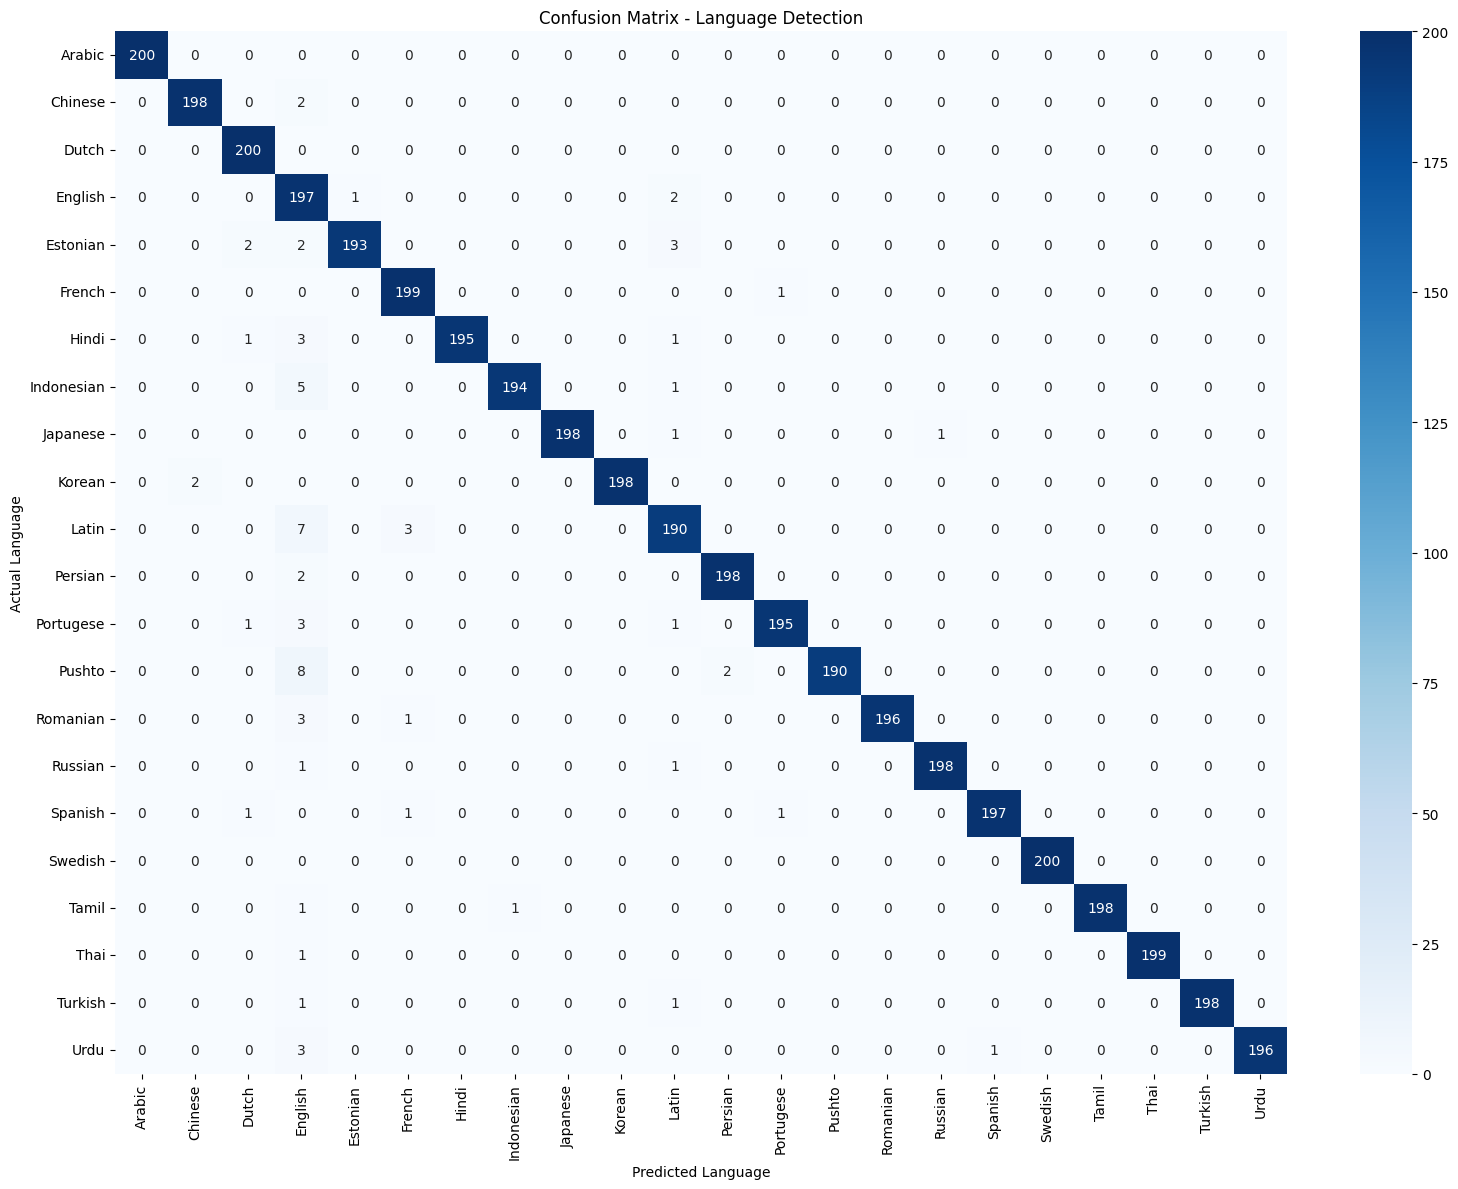

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

# Plot confusion matrix
plt.figure(figsize=(16, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel('Predicted Language')
plt.ylabel('Actual Language')
plt.title('Confusion Matrix - Language Detection')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
import os

project_path = "/content/language-detection"
os.makedirs(project_path, exist_ok=True)

print("Project folder ready:", project_path)


Project folder ready: /content/language-detection


In [ ]:
import shutil

shutil.copy(
    "/content/language_data/dataset.csv",
    "/content/language-detection/dataset.csv"
)

print("Dataset copied successfully")


Dataset copied successfully


In [ ]:
import os

project_path = "/content/language-detection"

# README
with open(f"{project_path}/README.md", "w") as f:
    f.write("""# Language Detection

Machine Learning project to predict the language of a text.

## Dataset
Dataset contains Text and language columns.

## Model
TF-IDF Vectorizer and Logistic Regression.

## Evaluation
Accuracy and Confusion Matrix.
""")

# Requirements
with open(f"{project_path}/requirements.txt", "w") as f:
    f.write("pandas\nscikit-learn\nmatplotlib\nseaborn\n")

# Git ignore
with open(f"{project_path}/.gitignore", "w") as f:
    f.write("__pycache__/\n*.pkl\n.env\n.ipynb_checkpoints/\n")

print(os.listdir(project_path))


['requirements.txt', 'dataset.csv', '.gitignore', 'README.md']


In [ ]:
import os

size_mb = os.path.getsize(
    "/content/language-detection/dataset.csv"
) / (1024 * 1024)

print(f"Dataset size: {size_mb:.2f} MB")


Dataset size: 12.39 MB


In [ ]:
%cd /content/language-detection

!git init
!git add README.md requirements.txt .gitignore
!git status


/content/language-detection
hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint: 
hint: 	git config --global init.defaultBranch <name>
hint: 
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint: 
hint: 	git branch -m <name>
Initialized empty Git repository in /content/language-detection/.git/
On branch master

No commits yet

Changes to be committed:
  (use "git rm --cached <file>..." to unstage)
	new file:   .gitignore
	new file:   README.md
	new file:   requirements.txt

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	dataset.csv



In [ ]:
!git config --global user.name "YOUR_GITHUB_USERNAME"
!git config --global user.email "YOUR_GITHUB_EMAIL"

!git commit -m "Add language detection project files"
!git branch -M main


[master (root-commit) 578971e] Add language detection project files
 3 files changed, 20 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 README.md
 create mode 100644 requirements.txt


In [ ]:
!git remote add origin https://github.com/YOUR_USERNAME/language-detection.git
!git push -u origin main

fatal: could not read Username for 'https://github.com': No such device or address


In [ ]:
%%writefile language_detection.py

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


Writing language_detection.py


Accuracy: 98.29545454545455 %


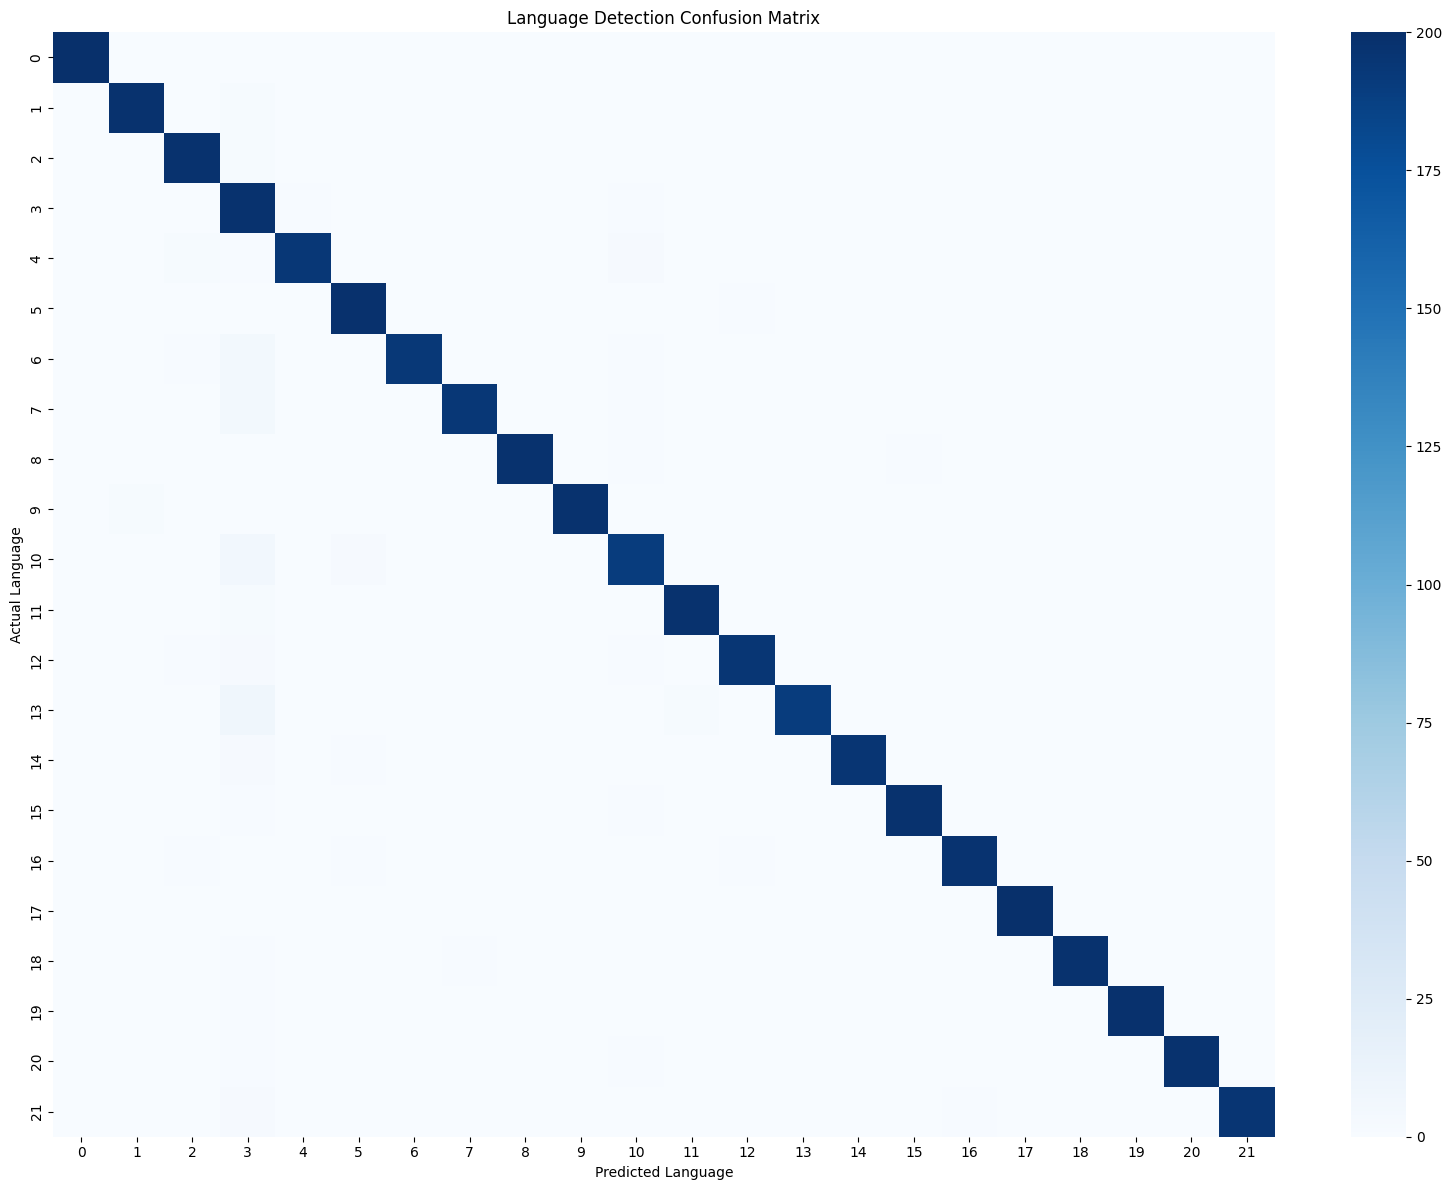

In [ ]:
# Load dataset
df = pd.read_csv('/content/language_data/dataset.csv')
df = df.dropna(subset=['Text', 'language'])

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    df['Text'],
    df['language'],
    test_size=0.2,
    random_state=42,
    stratify=df['language']
)

# Build model
model = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char', ngram_range=(1, 3))),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Train model
model.fit(X_train, y_train)

# Evaluate model
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(16, 12))
sns.heatmap(cm, cmap='Blues', annot=False)
plt.title('Language Detection Confusion Matrix')
plt.xlabel('Predicted Language')
plt.ylabel('Actual Language')
plt.tight_layout()
plt.show()
